# 4. Explainability

*Page 4 of 8.* [previous: 3. Classification](https://robinson-vidva.github.io/mb-methylation-xai/03_classification.html) | [index](https://robinson-vidva.github.io/mb-methylation-xai/) | [next: 5. Methylation versus expression](https://robinson-vidva.github.io/mb-methylation-xai/05_methylation_vs_expression.html)

A classifier that is right is not yet useful for biology. The question here is which CpG sites
carry each subgroup call, and whether those sites sit in genes that make sense.

**Integrated gradients** attribute a prediction to the input features. The method moves the input from
a baseline (here the mean training profile) to the actual tumour in small steps and sums the gradient
of the predicted class along the path. The result is one number per CpG: positive when the tumour's
methylation at that site pushes the call towards the class, negative when it pushes away.
Attributions were computed on the four-group MLP and averaged over the correctly classified training
tumours of each subgroup.

Each CpG is annotated from the Illumina manifest with its gene, its position relative to the gene
(promoter regions TSS200, TSS1500, 5'UTR and first exon; or gene body), and whether the subgroup is
hyper- or hypomethylated at that site relative to the other subgroups.

In [1]:
import json
import pandas as pd
from IPython.display import Image, display
from pathlib import Path
TAB = Path('../results/tables')
FIG = Path('../results/figures')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 90)

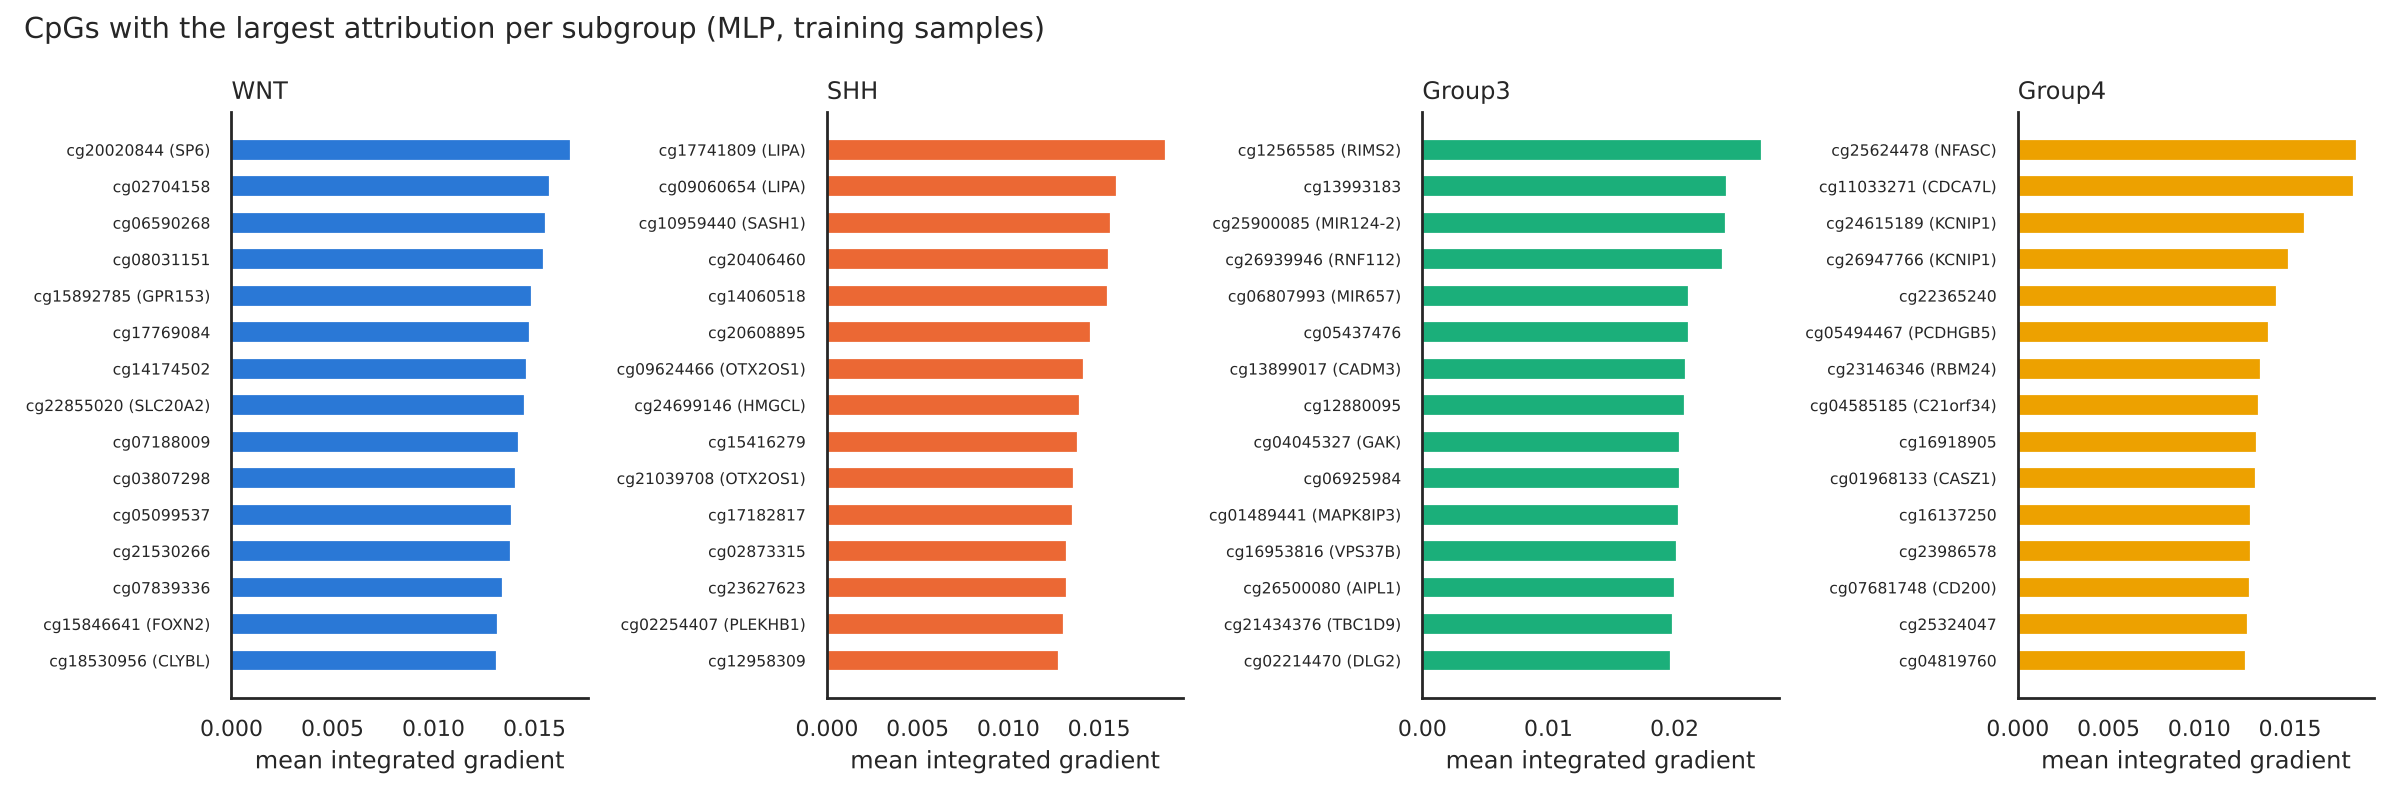

In [2]:
display(Image(FIG / 'top_cpgs_per_group.png'))

In [3]:
top = pd.read_csv(TAB / 'top_cpgs_per_group.csv')
top.groupby('group').head(10)[['group', 'cpg', 'gene', 'region', 'cpg_island', 'direction', 'mean_attribution', 'delta_beta_vs_rest']]

,group,cpg,gene,region,cpg_island,direction,mean_attribution,delta_beta_vs_rest
0,WNT,cg20020844,SP6,5'UTR,S_Shore,hypermethylated,0.01680,0.64205
1,WNT,cg02704158,NaN,NaN,N_Shore,hypermethylated,0.01575,0.68853
2,WNT,cg06590268,NaN,NaN,Island,hypermethylated,0.01559,0.61425
3,WNT,cg08031151,NaN,NaN,N_Shore,hypermethylated,0.01549,0.66551
4,WNT,cg15892785,GPR153,3'UTR,Island,hypermethylated,0.01489,0.60862
5,WNT,cg17769084,NaN,NaN,Island,hypermethylated,0.01480,0.66948
6,WNT,cg14174502,NaN,NaN,NaN,hypomethylated,0.01462,-0.61974
7,WNT,cg22855020,SLC20A2,5'UTR,NaN,hypomethylated,0.01451,-0.71315
8,WNT,cg07188009,NaN,NaN,S_Shelf,hypomethylated,0.01423,-0.59633
9,WNT,cg03807298,NaN,NaN,Island,hypermethylated,0.01410,0.75737


The full list, 50 CpGs per subgroup, is in `results/tables/top_cpgs_per_group.csv`.
Two things stand out. First, most top CpGs are hypomethylated in their subgroup. Loss of promoter
methylation switches a gene on, so the model mostly recognises subgroups by programs that are turned
on, not off. Second, many top CpGs sit in genes of neuronal and developmental identity rather than in
the known driver genes. This is expected. Drivers such as CTNNB1, PTCH1 or MYC are defined by mutation
or amplification. Methylation records lineage, and lineage is what separates the subgroups.

Whether these sites actually control expression is the question of the next page.

*Page 4 of 8.* [previous: 3. Classification](https://robinson-vidva.github.io/mb-methylation-xai/03_classification.html) | [index](https://robinson-vidva.github.io/mb-methylation-xai/) | [next: 5. Methylation versus expression](https://robinson-vidva.github.io/mb-methylation-xai/05_methylation_vs_expression.html)